# Male abstraction bias across languages: forest plot for the smaller concreteness norm sets

For each language with a smaller set of human concreteness norms (≈600–3,800 words) this notebook builds a gender axis in fastText's vectors for that language from five kinship/role seed pairs (Eq. S1, as in the Dutch, Estonian and Chinese replications), scores every rated word, and reports the correlation between the gender score and concreteness with a Fisher 95% CI, a held-out gendered-pair check, the extended ten-pair axis and the leave-one-pair-out range. The estimates are drawn as a forest plot together with the large-norm languages already reported in the supplement (and Croatian/Persian if their result folders exist next to this one).

**Languages and norms supplied (folder `norms\`):** Portuguese (Soares et al. 2017, 3,800), Spanish (Guasch et al. 2016 + Hinojosa et al. 2016, 2,141), French (Bonin et al. 2018, 1,659), Indonesian (Sianipar et al. 2016, 1,487), Italian (Montefinese et al. 2014, 1,121), Turkish (Göz et al. 2017, 568).

**Vectors expected in this folder:** `cc.pt.300.vec`, `cc.es.300.vec`, `cc.fr.300.vec`, `cc.id.300.vec`, `cc.it.300.vec`, `cc.tr.300.vec` (the unzipped text `.vec` files from https://fasttext.cc/docs/en/crawl-vectors.html). Languages whose file is missing are skipped with a message, so the notebook can be run incrementally.

**Requirements:** `pip install numpy pandas scipy matplotlib`

In [8]:
# ---------------------------------------------------------------- configuration
from pathlib import Path
import json
BASE  = Path.cwd()     # folder holding this notebook, the norms\ folder and the .vec files
NORMS = BASE / "norms"
OUT   = BASE / "results_forest"; OUT.mkdir(exist_ok=True)
# result folders of the Croatian and Persian notebooks (optional; used for two extra rows if present)
EXTRA_RESULTS = {"hr": BASE.parent / "croatian" / "results_hr" / "stats_hr.csv",
                 "fa": BASE.parent / "persian" / "results_fa" / "stats_fa.csv"}

LANGS = {
 "pt": {
  "name": "Portuguese",
  "norms": "pt_soares-2017.csv",
  "gender_system": "grammatical gender",
  "seeds": {
   "primary": [
    [
     "homem",
     "mulher"
    ],
    [
     "menino",
     "menina"
    ],
    [
     "masculino",
     "feminino"
    ],
    [
     "pai",
     "mãe"
    ],
    [
     "irmão",
     "irmã"
    ]
   ],
   "extended": [
    [
     "homem",
     "mulher"
    ],
    [
     "menino",
     "menina"
    ],
    [
     "masculino",
     "feminino"
    ],
    [
     "pai",
     "mãe"
    ],
    [
     "irmão",
     "irmã"
    ],
    [
     "filho",
     "filha"
    ],
    [
     "tio",
     "tia"
    ],
    [
     "rei",
     "rainha"
    ],
    [
     "senhor",
     "senhora"
    ],
    [
     "avô",
     "avó"
    ]
   ]
  },
  "validation": [
   [
    "marido",
    "esposa"
   ],
   [
    "noivo",
    "noiva"
   ],
   [
    "ator",
    "atriz"
   ],
   [
    "príncipe",
    "princesa"
   ],
   [
    "neto",
    "neta"
   ],
   [
    "sobrinho",
    "sobrinha"
   ],
   [
    "professor",
    "professora"
   ],
   [
    "homens",
    "mulheres"
   ],
   [
    "meninos",
    "meninas"
   ],
   [
    "rapaz",
    "rapariga"
   ]
  ]
 },
 "fr": {
  "name": "French",
  "norms": "fr_bonin-2018.csv",
  "gender_system": "grammatical gender",
  "seeds": {
   "primary": [
    [
     "homme",
     "femme"
    ],
    [
     "garçon",
     "fille"
    ],
    [
     "masculin",
     "féminin"
    ],
    [
     "père",
     "mère"
    ],
    [
     "frère",
     "sœur"
    ]
   ],
   "extended": [
    [
     "homme",
     "femme"
    ],
    [
     "garçon",
     "fille"
    ],
    [
     "masculin",
     "féminin"
    ],
    [
     "père",
     "mère"
    ],
    [
     "frère",
     "sœur"
    ],
    [
     "oncle",
     "tante"
    ],
    [
     "roi",
     "reine"
    ],
    [
     "monsieur",
     "madame"
    ],
    [
     "grand-père",
     "grand-mère"
    ],
    [
     "mari",
     "épouse"
    ]
   ]
  },
  "validation": [
   [
    "acteur",
    "actrice"
   ],
   [
    "prince",
    "princesse"
   ],
   [
    "neveu",
    "nièce"
   ],
   [
    "hommes",
    "femmes"
   ],
   [
    "garçons",
    "filles"
   ],
   [
    "chanteur",
    "chanteuse"
   ],
   [
    "directeur",
    "directrice"
   ],
   [
    "cousin",
    "cousine"
   ],
   [
    "copain",
    "copine"
   ],
   [
    "duc",
    "duchesse"
   ]
  ]
 },
 "id": {
  "name": "Indonesian",
  "norms": "id_sianipar-2016.csv",
  "gender_system": "genderless",
  "seeds": {
   "primary": [
    [
     "pria",
     "wanita"
    ],
    [
     "lelaki",
     "perempuan"
    ],
    [
     "ayah",
     "ibu"
    ],
    [
     "saudara",
     "saudari"
    ],
    [
     "putra",
     "putri"
    ]
   ],
   "extended": [
    [
     "pria",
     "wanita"
    ],
    [
     "lelaki",
     "perempuan"
    ],
    [
     "ayah",
     "ibu"
    ],
    [
     "saudara",
     "saudari"
    ],
    [
     "putra",
     "putri"
    ],
    [
     "paman",
     "bibi"
    ],
    [
     "raja",
     "ratu"
    ],
    [
     "tuan",
     "nyonya"
    ],
    [
     "kakek",
     "nenek"
    ],
    [
     "suami",
     "istri"
    ]
   ]
  },
  "validation": [
   [
    "cowok",
    "cewek"
   ],
   [
    "pemuda",
    "pemudi"
   ],
   [
    "mahasiswa",
    "mahasiswi"
   ],
   [
    "siswa",
    "siswi"
   ],
   [
    "dewa",
    "dewi"
   ],
   [
    "duda",
    "janda"
   ],
   [
    "aktor",
    "aktris"
   ],
   [
    "laki-laki",
    "perempuan"
   ],
   [
    "bapak",
    "ibu"
   ],
   [
    "pangeran",
    "putri"
   ]
  ]
 },
 "es": {
  "name": "Spanish",
  "norms": "es_guasch-2016_hinojosa-2016.csv",
  "gender_system": "grammatical gender",
  "seeds": {
   "primary": [
    [
     "hombre",
     "mujer"
    ],
    [
     "niño",
     "niña"
    ],
    [
     "masculino",
     "femenino"
    ],
    [
     "padre",
     "madre"
    ],
    [
     "hermano",
     "hermana"
    ]
   ],
   "extended": [
    [
     "hombre",
     "mujer"
    ],
    [
     "niño",
     "niña"
    ],
    [
     "masculino",
     "femenino"
    ],
    [
     "padre",
     "madre"
    ],
    [
     "hermano",
     "hermana"
    ],
    [
     "hijo",
     "hija"
    ],
    [
     "tío",
     "tía"
    ],
    [
     "rey",
     "reina"
    ],
    [
     "señor",
     "señora"
    ],
    [
     "abuelo",
     "abuela"
    ]
   ]
  },
  "validation": [
   [
    "marido",
    "esposa"
   ],
   [
    "novio",
    "novia"
   ],
   [
    "actor",
    "actriz"
   ],
   [
    "príncipe",
    "princesa"
   ],
   [
    "nieto",
    "nieta"
   ],
   [
    "sobrino",
    "sobrina"
   ],
   [
    "chico",
    "chica"
   ],
   [
    "profesor",
    "profesora"
   ],
   [
    "hombres",
    "mujeres"
   ],
   [
    "niños",
    "niñas"
   ]
  ]
 },
 "it": {
  "name": "Italian",
  "norms": "it_montefinese-2014.csv",
  "gender_system": "grammatical gender",
  "seeds": {
   "primary": [
    [
     "uomo",
     "donna"
    ],
    [
     "ragazzo",
     "ragazza"
    ],
    [
     "maschile",
     "femminile"
    ],
    [
     "padre",
     "madre"
    ],
    [
     "fratello",
     "sorella"
    ]
   ],
   "extended": [
    [
     "uomo",
     "donna"
    ],
    [
     "ragazzo",
     "ragazza"
    ],
    [
     "maschile",
     "femminile"
    ],
    [
     "padre",
     "madre"
    ],
    [
     "fratello",
     "sorella"
    ],
    [
     "figlio",
     "figlia"
    ],
    [
     "zio",
     "zia"
    ],
    [
     "re",
     "regina"
    ],
    [
     "signore",
     "signora"
    ],
    [
     "nonno",
     "nonna"
    ]
   ]
  },
  "validation": [
   [
    "marito",
    "moglie"
   ],
   [
    "attore",
    "attrice"
   ],
   [
    "principe",
    "principessa"
   ],
   [
    "uomini",
    "donne"
   ],
   [
    "ragazzi",
    "ragazze"
   ],
   [
    "bambino",
    "bambina"
   ],
   [
    "maestro",
    "maestra"
   ],
   [
    "cugino",
    "cugina"
   ],
   [
    "sposo",
    "sposa"
   ],
   [
    "duca",
    "duchessa"
   ]
  ]
 },
 "tr": {
  "name": "Turkish",
  "norms": "tr_goz-2017.csv",
  "gender_system": "genderless",
  "seeds": {
   "primary": [
    [
     "adam",
     "kadın"
    ],
    [
     "oğlan",
     "kız"
    ],
    [
     "erkek",
     "dişi"
    ],
    [
     "baba",
     "anne"
    ],
    [
     "ağabey",
     "abla"
    ]
   ],
   "extended": [
    [
     "adam",
     "kadın"
    ],
    [
     "oğlan",
     "kız"
    ],
    [
     "erkek",
     "dişi"
    ],
    [
     "baba",
     "anne"
    ],
    [
     "ağabey",
     "abla"
    ],
    [
     "dayı",
     "teyze"
    ],
    [
     "kral",
     "kraliçe"
    ],
    [
     "bey",
     "hanım"
    ],
    [
     "dede",
     "nine"
    ],
    [
     "damat",
     "gelin"
    ]
   ]
  },
  "validation": [
   [
    "koca",
    "karı"
   ],
   [
    "prens",
    "prenses"
   ],
   [
    "aktör",
    "aktris"
   ],
   [
    "erkekler",
    "kadınlar"
   ],
   [
    "amca",
    "hala"
   ],
   [
    "oğlanlar",
    "kızlar"
   ],
   [
    "babalar",
    "anneler"
   ],
   [
    "beyefendi",
    "hanımefendi"
   ],
   [
    "delikanlı",
    "bayan"
   ],
   [
    "kayınpeder",
    "kayınvalide"
   ]
  ]
 }
}

REFERENCE = [
 {
  "code": "nl",
  "name": "Dutch",
  "r": -0.268,
  "ci_lo": -0.279,
  "ci_hi": -0.256,
  "n": 23758,
  "gender_system": "common/neuter only",
  "source": "Supplementary Section (Dutch): spaCy nl vectors, Brysbaert et al. 2014"
 },
 {
  "code": "et",
  "name": "Estonian",
  "r": -0.124,
  "ci_lo": -0.135,
  "ci_hi": -0.114,
  "n": 33031,
  "gender_system": "genderless",
  "source": "Supplementary Section (Estonian): fastText cc.et, Proos & Aigro 2023"
 },
 {
  "code": "zh",
  "name": "Chinese",
  "r": -0.111,
  "ci_lo": -0.123,
  "ci_hi": -0.098,
  "n": 23961,
  "gender_system": "genderless",
  "source": "Supplementary Section (Chinese): spaCy zh vectors, Chan & Tse 2024"
 },
 {
  "code": "en",
  "name": "English (12-model mean, single words)",
  "r": -0.085,
  "ci_lo": -0.131,
  "ci_hi": -0.039,
  "n": 39953,
  "gender_system": "natural gender (pronouns only)",
  "source": "Supplementary Table 3: mean of 12 models, CI across models"
 }
]
print("norms folder:", NORMS, "| vectors present:", [c for c in LANGS if (BASE / f"cc.{c}.300.vec").exists()])

norms folder: C:\Users\dguilb\Desktop\replication_folders\folders\forest plot replication\norms | vectors present: ['pt', 'fr', 'id', 'it', 'tr']


In [9]:
# ---------------------------------------------------------------- helpers
import time, re
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200)

def normalize(w): return str(w).strip().replace("\u064a", "\u06cc").replace("\u0643", "\u06a9").replace("\u200c", "")

def unit(v):
    n = np.linalg.norm(v); return v / n if n > 0 else v
def fisher_ci(r, n):
    if n < 4 or abs(r) >= 1: return (np.nan, np.nan)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3); q = stats.norm.ppf(0.975); return tuple(np.tanh([z - q * se, z + q * se]))

def load_vectors(path, needed, code):
    needed = {normalize(w) for w in needed}; needed |= {w.lower() for w in needed}
    vec, dim = {}, None
    with open(path, "rt", encoding="utf8", errors="ignore") as f:
        for i, line in enumerate(f):
            p = line.rstrip("\r\n").split(" ")
            if i == 0 and len(p) == 2: dim = int(p[1]); continue
            if dim is None: dim = len(p) - 1
            w = normalize(" ".join(p[:len(p) - dim]))
            if w in needed and w not in vec: vec[w] = np.array(p[len(p) - dim:], dtype=np.float32)
    def lookup(w):
        w = normalize(w)
        for cand in (w, w.lower()):
            v = vec.get(cand)
            if v is not None: return v
        return None
    return lookup, len(vec)

def gender_axis(lookup, pairs):
    diffs, used = [], []
    for m, f in pairs:
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None: continue
        diffs.append(unit(vm) - unit(vf)); used.append((m, f))
    if not diffs: raise RuntimeError("no seed pairs available")
    return unit(np.mean(diffs, axis=0)), used

def score(lookup, axis, words):
    g = np.full(len(words), np.nan)
    for i, w in enumerate(words):
        v = lookup(w)
        if v is not None: g[i] = float(unit(v) @ axis)
    return g

def corr(g, conc):
    ok = np.isfinite(g)
    if ok.sum() < 10: return dict(r=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan, n=int(ok.sum()))
    r, p = stats.pearsonr(g[ok], conc[ok]); lo, hi = fisher_ci(r, ok.sum())
    return dict(r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()))

## 1. One estimate per language

In [10]:
rows = []
for code, L in LANGS.items():
    vecfile = BASE / f"cc.{code}.300.vec"
    if not vecfile.exists():
        print(f"[{L['name']}] {vecfile.name} not found - skipped"); continue
    norms = pd.read_csv(NORMS / L["norms"], keep_default_na=False, na_values=[""])
    norms["word"] = norms.word.map(normalize); norms["conc"] = pd.to_numeric(norms.conc, errors="coerce")
    norms = norms[(norms.word != "") & norms.conc.notna()].reset_index(drop=True)
    needed = set(norms.word) | {w for s in L["seeds"].values() for p in s for w in p} | {w for p in L["validation"] for w in p}
    t0 = time.time(); lookup, kept = load_vectors(vecfile, needed, code)
    prim, ext = [tuple(p) for p in L["seeds"]["primary"]], [tuple(p) for p in L["seeds"]["extended"]]
    axis, used = gender_axis(lookup, prim); g = score(lookup, axis, norms.word.tolist()); c = corr(g, norms.conc.values)
    axis_e, used_e = gender_axis(lookup, ext); ge = score(lookup, axis_e, norms.word.tolist()); ce = corr(ge, norms.conc.values)
    hits = [float(unit(lookup(m)) @ axis) > float(unit(lookup(f)) @ axis) for m, f in L["validation"]
            if (m, f) not in used and lookup(m) is not None and lookup(f) is not None]
    loo = []
    for p in prim:
        sub = [q for q in prim if q != p]
        try: a, _ = gender_axis(lookup, sub); loo.append(corr(score(lookup, a, norms.word.tolist()), norms.conc.values)["r"])
        except RuntimeError: pass
    d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
    rows.append(dict(code=code, name=L["name"], gender_system=L["gender_system"], n_rated=len(norms), coverage=c["n"] / len(norms),
                     seed_pairs=f"{len(used)}/{len(prim)}", validation_acc=np.mean(hits) if hits else np.nan, validation_n=len(hits),
                     r=c["r"], ci_lo=c["ci_lo"], ci_hi=c["ci_hi"], p=c["p"], n=c["n"],
                     r_extended=ce["r"], ci_lo_extended=ce["ci_lo"], ci_hi_extended=ce["ci_hi"], seed_pairs_extended=f"{len(used_e)}/{len(ext)}",
                     loo_min=min(loo) if loo else np.nan, loo_max=max(loo) if loo else np.nan,
                     most_female=", ".join(d.w.head(6)), most_male=", ".join(d.w.tail(6)[::-1]), source=norms["source"].iloc[0] if "source" in norms else ""))
    print(f"[{L['name']}] {c['n']:,}/{len(norms):,} words scored ({c['n']/len(norms):.0%}); seeds {len(used)}/{len(prim)}; "
          f"r = {c['r']:+.3f} [{c['ci_lo']:+.3f}, {c['ci_hi']:+.3f}]; extended r = {ce['r']:+.3f}; held-out pairs {np.mean(hits) if hits else float('nan'):.2f} (n={len(hits)}); {time.time()-t0:.0f} s")
RES = pd.DataFrame(rows)
RES.to_csv(OUT / "forest_estimates.csv", index=False)
RES[["name", "gender_system", "n", "coverage", "seed_pairs", "validation_acc", "r", "ci_lo", "ci_hi", "r_extended", "loo_min", "loo_max"]].round(3)

[Portuguese] 3,800/3,800 words scored (100%); seeds 5/5; r = -0.039 [-0.071, -0.008]; extended r = -0.061; held-out pairs 1.00 (n=10); 77 s
[French] 1,633/1,659 words scored (98%); seeds 5/5; r = -0.118 [-0.166, -0.070]; extended r = -0.141; held-out pairs 1.00 (n=10); 82 s
[Indonesian] 1,428/1,487 words scored (96%); seeds 5/5; r = -0.027 [-0.079, +0.025]; extended r = +0.054; held-out pairs 1.00 (n=10); 2703 s
[Spanish] cc.es.300.vec not found - skipped
[Italian] 1,114/1,121 words scored (99%); seeds 5/5; r = -0.187 [-0.243, -0.129]; extended r = -0.203; held-out pairs 1.00 (n=10); 63 s
[Turkish] 568/568 words scored (100%); seeds 5/5; r = -0.244 [-0.320, -0.165]; extended r = -0.192; held-out pairs 1.00 (n=10); 82 s


,name,gender_system,n,coverage,seed_pairs,validation_acc,r,ci_lo,ci_hi,r_extended,loo_min,loo_max
0,Portuguese,grammatical gender,3800,1.000,5/5,1.0,-0.039,-0.071,-0.008,-0.061,-0.063,-0.019
1,French,grammatical gender,1633,0.984,5/5,1.0,-0.118,-0.166,-0.070,-0.141,-0.145,-0.091
2,Indonesian,genderless,1428,0.960,5/5,1.0,-0.027,-0.079,0.025,0.054,-0.118,0.033
3,Italian,grammatical gender,1114,0.994,5/5,1.0,-0.187,-0.243,-0.129,-0.203,-0.205,-0.162
4,Turkish,genderless,568,1.000,5/5,1.0,-0.244,-0.320,-0.165,-0.192,-0.324,-0.150


## 2. Words at the two extremes

Worth a look for every language before trusting its estimate: a valid axis has words for women at one end and words for men (or male-coded roles) at the other; function words, plurals or an unrelated register at either end mean a seed word is ambiguous in that language (as *zij*/*haar* were in Dutch).

In [11]:
for _, r in RES.iterrows():
    print(f"{r['name']:12s} F: {r.most_female}\n{'':12s} M: {r.most_male}\n")

Portuguese   F: mulher, rainha, freira, lésbica, mãe, parteira
             M: velho, malvado, irmão, pai, homem, sábio

French       F: mère, reine, soeur, fille, tante, dame
             M: seul, homme, bougre, frère, ours, doué

Indonesian   F: anggun, cantik, kecantikan, gaun, ibu, wanita
             M: paman, berkelahi, ayah, abang, tampan, jagoan

Italian      F: donna, ragazza, regina, suora, madre, prostituta
             M: fratello, amico, padre, malvagio, ragazzo, odioso

Turkish      F: hamile, kadın, kelebek, makyaj, hormon, papatya
             M: dede, baba, prensip, yağcılık, espri, berber



## 3. Forest plot with the large-norm languages

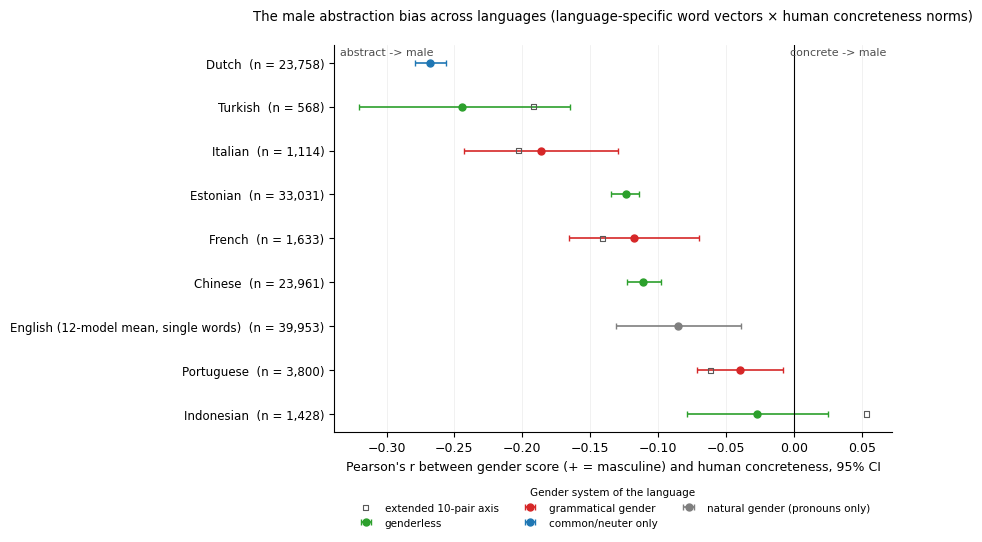

,name,gender_system,r,ci_lo,ci_hi,n
0,Dutch,common/neuter only,-0.268,-0.279,-0.256,23758
1,Turkish,genderless,-0.244,-0.320,-0.165,568
2,Italian,grammatical gender,-0.187,-0.243,-0.129,1114
3,Estonian,genderless,-0.124,-0.135,-0.114,33031
4,French,grammatical gender,-0.118,-0.166,-0.070,1633
5,Chinese,genderless,-0.111,-0.123,-0.098,23961
6,"English (12-model mean, single words)",natural gender (pronouns only),-0.085,-0.131,-0.039,39953
7,Portuguese,grammatical gender,-0.039,-0.071,-0.008,3800
8,Indonesian,genderless,-0.027,-0.079,0.025,1428


In [12]:
ref = pd.DataFrame(REFERENCE)
extra = []
for code, path in EXTRA_RESULTS.items():
    if path.exists():
        s = pd.read_csv(path); s = s[(s.seeds == "primary") & (s.specification == "all terms (no controls)")].iloc[0]
        extra.append(dict(code=code, name={"hr": "Croatian", "fa": "Persian"}[code], r=s.r, ci_lo=s.ci_lo, ci_hi=s.ci_hi, n=int(s.n),
                          gender_system={"hr": "grammatical gender", "fa": "genderless"}[code], source=str(path)))
ALL = pd.concat([ref, pd.DataFrame(extra), RES[["code", "name", "r", "ci_lo", "ci_hi", "n", "gender_system", "source", "r_extended"]]], ignore_index=True)
ALL = ALL.sort_values("r").reset_index(drop=True)
ALL.to_csv(OUT / "forest_all_languages.csv", index=False)

colors = {"genderless": "#2ca02c", "grammatical gender": "#d62728", "common/neuter only": "#1f77b4", "natural gender (pronouns only)": "#7f7f7f"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(7.2, 0.38 * len(ALL) + 1.6))
y = np.arange(len(ALL))[::-1]
for gs_, col in colors.items():
    m = ALL.gender_system == gs_
    if not m.any(): continue
    r_, lo_, hi_ = ALL.r[m].to_numpy(float), ALL.ci_lo[m].to_numpy(float), ALL.ci_hi[m].to_numpy(float)
    ax.errorbar(r_, y[m], xerr=[r_ - lo_, hi_ - r_], fmt="o", ms=5, color=col, ecolor=col, elinewidth=1.2, capsize=2, label=gs_)
if "r_extended" in ALL:
    m = ALL.r_extended.notna(); ax.scatter(ALL.r_extended[m].to_numpy(float), y[m], marker="s", s=14, facecolors="none", edgecolors="0.35", linewidths=0.8, zorder=3, label="extended 10-pair axis")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([f"{n}  (n = {int(k):,})" for n, k in zip(ALL.name, ALL.n)], fontsize=8.5)
ax.set_xlabel("Pearson's r between gender score (+ = masculine) and human concreteness, 95% CI")
ax.text(0.01, 0.995, "abstract -> male", transform=ax.transAxes, fontsize=8, color="0.3", va="top")
ax.text(0.99, 0.995, "concrete -> male", transform=ax.transAxes, fontsize=8, color="0.3", va="top", ha="right")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=7.5, frameon=False, title="Gender system of the language", title_fontsize=7.5)
ax.grid(axis="x", alpha=0.25, lw=0.5)
ax.set_title("The male abstraction bias across languages (language-specific word vectors × human concreteness norms)", fontsize=9.5, pad=18)
for ext in ("png", "pdf"): fig.savefig(OUT / f"figS_forest_languages.{ext}", dpi=300, bbox_inches="tight")
plt.show()
ALL[["name", "gender_system", "r", "ci_lo", "ci_hi", "n"]].round(3)

## 4. Sign test across languages

With one estimate per language, the simplest cross-linguistic summary is how many of the languages show a negative correlation (and how many are significantly negative), plus a two-tailed binomial sign test.

In [14]:
k_neg = int((ALL.r < 0).sum()); k_sig = int((ALL.ci_hi < 0).sum()); N = int(ALL.r.notna().sum())
print(f"{k_neg} of {N} languages negative ({k_sig} with the 95% CI excluding zero); two-tailed binomial P = {stats.binomtest(k_neg, N, 0.5).pvalue:.2e}")
print(f"median r across languages = {ALL.r.median():+.3f}; range {ALL.r.min():+.3f} to {ALL.r.max():+.3f}")

9 of 9 languages negative (8 with the 95% CI excluding zero); two-tailed binomial P = 3.91e-03
median r across languages = -0.118; range -0.268 to -0.027
